In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sentence_transformers import SentenceTransformer,InputExample, losses
from sentence_transformers.evaluation import EmbeddingSimilarityEvaluator
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader
from sklearn.metrics import mean_absolute_error, mean_squared_error, classification_report
import json, warnings
warnings.filterwarnings('ignore')
print("Libraries imported")

Libraries imported


/tmp/ipykernel_9544/1350754698.py:5: DeprecationWarning: Importing from 'sentence_transformers.losses' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.losses' instead.
  from sentence_transformers import SentenceTransformer,InputExample, losses
/tmp/ipykernel_9544/1350754698.py:6: DeprecationWarning: Importing from 'sentence_transformers.evaluation' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.evaluation' instead.
  from sentence_transformers.evaluation import EmbeddingSimilarityEvaluator


In [2]:
df = pd.read_csv("/content/cleaned_resumeJD_pairs.csv")
print(f'loaded: {len(df)} pairs')
print(f'\nlabel distribution')
print(df['match_label'].value_counts())
print(f'\nScore Range: {df["match_score"].min():.2f} - {df["match_label"]}')
df.head(3)

loaded: 280 pairs

label distribution
match_label
medium    110
high       93
low        77
Name: count, dtype: int64

Score Range: 0.06 - 0      medium
1         low
2         low
3      medium
4        high
        ...  
275       low
276       low
277      high
278    medium
279    medium
Name: match_label, Length: 280, dtype: object


,resume_text,job_description,match_label,match_score,match_label_lower,resume_len,jd_len
0,BI Analyst with 7 years of experience based in...,Fathom is hiring a Financial Analyst (Berlin)....,medium,0.53,medium,75,71
1,Data Scientist with 13 years of experience bas...,Lumen is hiring a Senior UX Designer (Singapor...,low,0.26,low,79,74
2,Software Engineer with 8 years of experience b...,Acme Corp is hiring a Product Manager (Seattle...,low,0.31,low,71,80


In [3]:
train_df, temp_df = train_test_split(
    df, test_size=0.3, random_state=42, stratify=df['match_label']
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, random_state=42, stratify=temp_df['match_label']
)
print(f'train: {len(train_df)} pairs')
print(f'val: {len(val_df)} pairs')
print(f'test: {len(test_df)} pairs')

# Verify each split has all 3 labels
for name, split in [('train', train_df), ('val', val_df), ('test', test_df)]:
    print(f'\n{name} label distribution')
    print(split['match_label'].value_counts())

train: 196 pairs
val: 42 pairs
test: 42 pairs

train label distribution
match_label
medium    77
high      65
low       54
Name: count, dtype: int64

val label distribution
match_label
medium    16
high      14
low       12
Name: count, dtype: int64

test label distribution
match_label
medium    17
high      14
low       11
Name: count, dtype: int64


In [5]:
# Convert to InputExample format- sentence transformer expect this
# text1 = resume, text2 = job description, label = match_score(float 0-1)

train_examples = [
    InputExample(texts=[row['resume_text'], row['job_description']], label=float(row['match_score']))
    for _, row in train_df.iterrows()
]
val_examples = [
    InputExample(texts=[row['resume_text'], row['job_description']], label=float(row['match_score']))
    for _, row in val_df.iterrows()
]

print(f'train examples: {len(train_examples)}')
print(f'val examples: {len(val_examples)}')
print(f'\nSample InputExample:')
print(f' text1 (resume): {train_examples[0].texts[0]}')
print(f' text2 (jd): {train_examples[0].texts[1]}')
print(f' label: {train_examples[0].label}')

train examples: 196
val examples: 42

Sample InputExample:
 text1 (resume): Site Reliability Engineer with 6 years of experience based in Toronto. M.S. in Human-Computer Interaction. Previously at TechNova and Cobalt, where I helped to improve system reliability, monitoring, and alerting, manage cloud infrastructure with infrastructure-as-code, and reduce incident response time and toil. Core skills include Ansible, AWS, Prometheus, Docker, Python, Terraform, and Linux. Proven track record of delivering results in fast-paced environments and collaborating across teams to drive measurable impact.
 text2 (jd): TechNova is hiring a Associate Product Manager (Seattle). In this role you will gather and synthesize customer and market feedback, align stakeholders around a product vision, own the product roadmap and prioritize the backlog, and define product requirements and success metrics. We are looking for 2+ years of experience and strong skills in roadmap planning, SQL, stakeholder manag

In [6]:
print('Loading Base BERT model')
base_model = SentenceTransformer('all-mpnet-base-v2')
print('Model Loaded Succesfully')

Loading Base BERT model


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Model Loaded Succesfully


In [9]:
# Evaluate Base model on test set BEFORE Fine Tuning
# This is our baseline, fine-tuning should beating this.
print('Evaluating base model on test set...')

base_preds = []
for _, row in test_df.iterrows():
    emb1 = base_model.encode(row['resume_text']).reshape(1, -1)
    emb2 = base_model.encode(row['job_description']).reshape(1, -1)
    sim = cosine_similarity(emb1, emb2)[0][0]
    base_preds.append(sim)

base_mae = mean_absolute_error(test_df['match_score'], base_preds)
base_rmse = np.sqrt(mean_squared_error(test_df['match_score'], base_preds))
print(f'\nBase Model Performance')
print(f'MAE: {base_mae:.4f}')
print(f'RMSE: {base_rmse:.4f}')
print()
print('Goal: Fine tuning should reduce MAE below this number')

Evaluating base model on test set...

Base Model Performance
MAE: 0.1946
RMSE: 0.2332

Goal: Fine tuning should reduce MAE below this number


In [11]:
model = SentenceTransformer('all-mpnet-base-v2')
train_dataloader = DataLoader(train_examples, shuffle=True, batch_size=16)
train_loss = losses.CosineSimilarityLoss(model)

evaluator = EmbeddingSimilarityEvaluator.from_input_examples(
    val_examples,
    name='ats_val'
)

print('Traning Setup Ready.')
print(f'Batch Size: 16')
print(f'Training Pairs: {len(train_examples)}')
print(f'Steps/Epoch: {len(train_dataloader)}')

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Traning Setup Ready.
Batch Size: 16
Training Pairs: 196
Steps/Epoch: 13


In [13]:
total_steps = len(train_dataloader) * 10
warmup_steps = int(total_steps * 0.1)

print(f'Total Steps: {total_steps}')
print(f'Warmup Steps: {warmup_steps}')
print(f'\nStarting Fine-Tuning...\n')

model.fit(
    train_objectives=[(train_dataloader, train_loss)],
    evaluator=evaluator,
    epochs=11,
    evaluation_steps=len(train_dataloader),
    warmup_steps=warmup_steps,
    output_path='./my_ats_model',
    save_best_model=True,
    use_amp=True,
    show_progress_bar=True

)
print('\m FINE-TUNING-COMPLETED!!!!')

Total Steps: 130
Warmup Steps: 13

Starting Fine-Tuning...



Computing widget examples:   0%|          | 0/1 [00:00<?, ?example/s]

Step,Training Loss,Validation Loss,Ats Val Pearson Cosine,Ats Val Spearman Cosine
13,No log,No log,0.708903,0.698318
26,No log,No log,0.738686,0.729779
39,No log,No log,0.753801,0.722319
52,No log,No log,0.763189,0.763754
65,No log,No log,0.768040,0.759943
78,No log,No log,0.768961,0.760754
91,No log,No log,0.769970,0.763836
104,No log,No log,0.773898,0.760835
117,No log,No log,0.775630,0.765295
130,No log,No log,0.776271,0.764728


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

\m FINE-TUNING-COMPLETED!!!!


In [14]:
fine_tuned_model = SentenceTransformer('./my_ats_model')
print('Fine Tuned Model Loaded')

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Fine Tuned Model Loaded


In [15]:
ft_preds = []
for _, row in test_df.iterrows():
  emb1 = fine_tuned_model.encode(row['resume_text']).reshape(1, -1)
  emb2 = fine_tuned_model.encode(row['job_description']).reshape(1, -1)
  sim = cosine_similarity(emb1, emb2)[0][0]
  ft_preds.append(sim)

ft_mae = mean_absolute_error(test_df['match_score'], ft_preds)
ft_rmse = np.sqrt(mean_squared_error(test_df['match_score'], ft_preds))
print(f'\nFine Tuned Model Performance')
print(f'MAE: {ft_mae:.4f}')
print(f'RMSE: {ft_rmse:.4f}')


Fine Tuned Model Performance
MAE: 0.0981
RMSE: 0.1226


In [17]:
# Calculate and print improvement percentages
mae_improvement = ((base_mae - ft_mae) / base_mae) * 100
rmse_improvement = ((base_rmse - ft_rmse) / base_rmse) * 100

print('=' * 50)
print('PERFORMANCE IMPROVEMENT')
print('=' * 50)
print(f'MAE Improvement: {mae_improvement:.2f}%')
print(f'RMSE Improvement: {rmse_improvement:.2f}%')
print('=' * 50)

PERFORMANCE IMPROVEMENT
MAE Improvement: 49.59%
RMSE Improvement: 47.44%


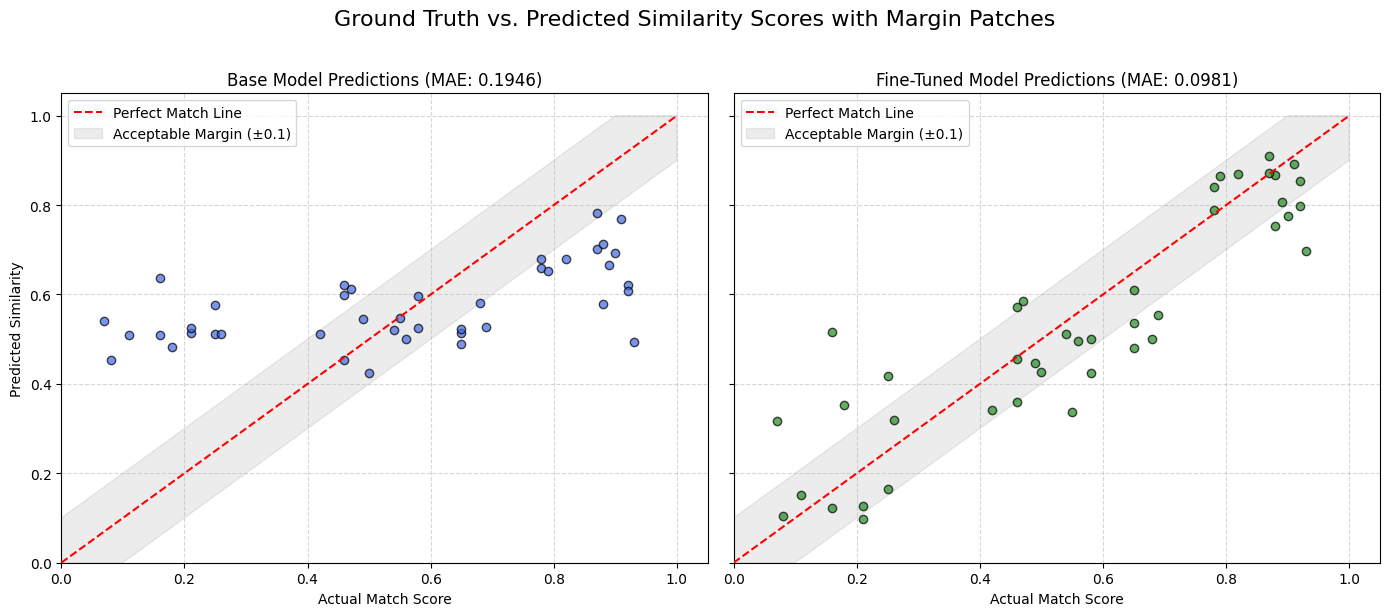

In [22]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

# Create a side-by-side scatter plot comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

y_true = test_df['match_score'].values

# 1. Base Model Scatter Plot
axes[0].scatter(y_true, base_preds, color='royalblue', alpha=0.7, edgecolors='k', zorder=3)
axes[0].plot([0, 1], [0, 1], '--', color='red', label='Perfect Match Line', zorder=4)

# Add a patch/polygon showing the perfect alignment margin (+/- 0.1)
margin_patch_base = patches.Polygon(
    [[0, 0.1], [0.9, 1.0], [1.0, 1.0], [1.0, 0.9], [0.1, 0.0], [0.0, 0.0]],
    closed=True, fill=True, color='gray', alpha=0.15, label='Acceptable Margin (±0.1)'
)
axes[0].add_patch(margin_patch_base)
axes[0].set_title(f'Base Model Predictions (MAE: {base_mae:.4f})')
axes[0].set_xlabel('Actual Match Score')
axes[0].set_ylabel('Predicted Similarity')
axes[0].set_xlim([0, 1.05])
axes[0].set_ylim([0, 1.05])
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend()

# 2. Fine-Tuned Model Scatter Plot
axes[1].scatter(y_true, ft_preds, color='forestgreen', alpha=0.7, edgecolors='k', zorder=3)
axes[1].plot([0, 1], [0, 1], '--', color='red', label='Perfect Match Line', zorder=4)

margin_patch_ft = patches.Polygon(
    [[0, 0.1], [0.9, 1.0], [1.0, 1.0], [1.0, 0.9], [0.1, 0.0], [0.0, 0.0]],
    closed=True, fill=True, color='gray', alpha=0.15, label='Acceptable Margin (±0.1)'
)
axes[1].add_patch(margin_patch_ft)
axes[1].set_title(f'Fine-Tuned Model Predictions (MAE: {ft_mae:.4f})')
axes[1].set_xlabel('Actual Match Score')
axes[1].set_xlim([0, 1.05])
axes[1].set_ylim([0, 1.05])
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend()

plt.suptitle('Ground Truth vs. Predicted Similarity Scores with Margin Patches', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

In [34]:
import os
import json

# Create the output directory if it doesn't exist
os.makedirs('models/my_ats_bert', exist_ok=True)

# Saving The Model
meta_data = {
    'base_model': 'all-mpnet-base-v2',
    'fine_tuned_model': 'my_ats_model',
    'dataset': 'cleaned_resumeJD_pairs.csv',
    'total_pairs': len(df),
    'train_pairs': len(train_df),
    'val_pairs': len(val_df),
    'test_pairs': len(test_df),
    'base_mae': base_mae,
    'epochs': 11,
    'batch_size': 16,
    'fine_tuned_mae': ft_mae,
    'improvement_pct': round((base_mae - ft_mae) / base_mae * 100, 2)
}

with open('/content/my_ats_model/meta_data.json', 'w') as f:
    json.dump(meta_data, f, indent=2)

print('Saved directory created and metadata written to: models/my_ats_bert/meta_data.json')
print(json.dumps(meta_data, indent=2))

Saved directory created and metadata written to: models/my_ats_bert/meta_data.json
{
  "base_model": "all-mpnet-base-v2",
  "fine_tuned_model": "my_ats_model",
  "dataset": "cleaned_resumeJD_pairs.csv",
  "total_pairs": 280,
  "train_pairs": 196,
  "val_pairs": 42,
  "test_pairs": 42,
  "base_mae": 0.19464273861476353,
  "epochs": 11,
  "batch_size": 16,
  "fine_tuned_mae": 0.09812468112224625,
  "improvement_pct": 49.59
}


In [36]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/my_ats_model",
    "zip",
    root_dir="/content",
    base_dir="my_ats_model"
)

files.download("/content/my_ats_model.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [39]:
# Production Pipeline Test for ATS Match
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

def run_pipeline_inference(model, jd, resume):
    jd_emb = model.encode(jd).reshape(1, -1)
    res_emb = model.encode(resume).reshape(1, -1)
    return float(cosine_similarity(res_emb, jd_emb)[0][0])

# Define testing suite
test_pipeline_cases = [
    {
        "id": "CASE_01_HIGH",
        "expected": "High Match (Expected: ~0.80+)",
        "jd": "Senior Data Scientist with 5+ years of experience. Machine Learning, NLP, Python, and PyTorch.",
        "resume": "Senior ML Engineer with 6 years experience specializing in NLP, training models with PyTorch and Python."
    },
    {
        "id": "CASE_02_MEDIUM",
        "expected": "Medium Match (Expected: ~0.50 - 0.75)",
        "jd": "Senior Data Scientist with 5+ years of experience. Machine Learning, NLP, Python, and PyTorch.",
        "resume": "Software Developer with 4 years experience. Strong Python and SQL developer with basic ML projects."
    },
    {
        "id": "CASE_03_LOW",
        "expected": "Low Match (Expected: <0.50)",
        "jd": "Senior Data Scientist with 5+ years of experience. Machine Learning, NLP, Python, and PyTorch.",
        "resume": "Professional Graphic Designer with 7 years of experience in Figma, Photoshop, and User Interface layouts."
    }
]

print("=" * 95)
print(f"{'ID':<15} | {'Expected Category':<35} | {'Base Score':<12} | {'Fine-Tuned Score':<15}")
print("=" * 95)

for case in test_pipeline_cases:
    base_score = run_pipeline_inference(base_model, case["jd"], case["resume"])
    ft_score = run_pipeline_inference(fine_tuned_model, case["jd"], case["resume"])
    print(f"{case['id']:<15} | {case['expected']:<35} | {base_score:<12.4f} | {ft_score:<15.4f}")
print("=" * 95)

ID              | Expected Category                   | Base Score   | Fine-Tuned Score
CASE_01_HIGH    | High Match (Expected: ~0.80+)       | 0.8268       | 0.7962         
CASE_02_MEDIUM  | Medium Match (Expected: ~0.50 - 0.75) | 0.7662       | 0.5587         
CASE_03_LOW     | Low Match (Expected: <0.50)         | 0.6136       | 0.2164         


Completed Fine Tuning And Model Related Work....💯💖